In [292]:
import pandas as pd
import matplotlib.pyplot as plt
pubg_stat = pd.read_csv('my_dataset.csv')

# pubg_stat['game_size'].describe()
# pubg_stat['player_dist_walk'].describe()
pubg_stat.columns

# max(pubg_stat['player_survive_time'])

Index(['date', 'game_size', 'match_id', 'match_mode', 'party_size',
       'player_assists', 'player_dbno', 'player_dist_ride', 'player_dist_walk',
       'player_dmg', 'player_kills', 'player_name', 'player_survive_time',
       'team_id', 'team_placement'],
      dtype='object')

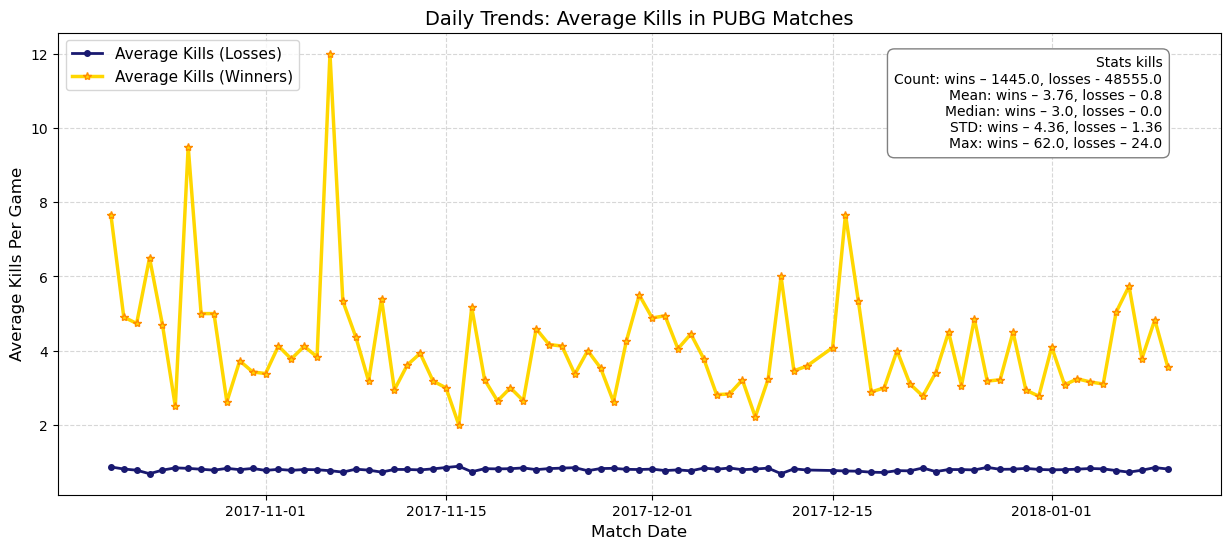

In [293]:
pubg_stat['date_dt'] = pd.to_datetime(pubg_stat['date']) #This line converts type of column to date

pubg_stat['only_date'] = pubg_stat['date_dt'].dt.date #Takes only date to new column

pubg_stat['time_of_day_hours'] = pubg_stat['date_dt'].dt.hour + pubg_stat['date_dt'].dt.minute / 60 #Converts to float hours of day
wins = pubg_stat[pubg_stat['team_placement'] == 1]
losses = pubg_stat[pubg_stat['team_placement'] > 1]

loss_kills = losses['player_kills']
win_kills = wins['player_kills']

stats_win_kills = win_kills.describe()
stats_losses_kills = loss_kills.describe()

box_text = ( 
    f"Stats kills\n"
    f"Count: wins – {stats_win_kills['count']}, losses - {round(stats_losses_kills['count'], 2)}\n"
    f"Mean: wins – {round(stats_win_kills['mean'], 2)}, losses – {round(stats_losses_kills['mean'], 2)}\n"
    f"Median: wins – {round(stats_win_kills['50%'], 2)}, losses – {round(stats_losses_kills['50%'], 2)}\n"
    f"STD: wins – {round(stats_win_kills['std'], 2)}, losses – {round(stats_losses_kills['std'], 2)}\n"
    f"Max: wins – {stats_win_kills['max']}, losses – {round(stats_losses_kills['max'], 2)}"
) #This is text box with some statistics

daily_loss_kills = losses.groupby('only_date')['player_kills'].mean() #This join the dates and mean kills on this day

daily_win_kills = wins.groupby('only_date')['player_kills'].mean() #Like previous


plt.figure(figsize=(15, 6))

plt.plot(daily_loss_kills.index, daily_loss_kills.values, 
         color='midnightblue', 
         linestyle='-', 
         linewidth=2, 
         marker='o',         
         markersize=4,
         label='Average Kills (Losses)')

plt.plot(daily_win_kills.index, daily_win_kills.values, 
         color='gold', 
         linestyle='-', 
         linewidth=2.5, 
         marker='*',         
         markersize=6,
         markeredgecolor='darkorange',
         label='Average Kills (Winners)')

plt.title('Daily Trends: Average Kills in PUBG Matches', fontsize=14)
plt.xlabel('Match Date', fontsize=12)
plt.ylabel('Average Kills Per Game', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)

plt.text(0.95, 0.95, box_text, transform=plt.gca().transAxes, 
         fontsize=10, verticalalignment='top', horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1, edgecolor='gray')) #This part put a text box with stat on plot

plt.legend(fontsize=11, loc='upper left')

plt.show()
# stats_win
# print(daily_win_kills.values)

The sample consists of 50,000 players, of whom only 2.9% are winners (1,445 wins versus 48,555 losses).

The average number of kills per game is 3.76 for winners and 0.8 for losers. The median for losers is zero, meaning more than half of them get no kills at all. The winners’ distribution has a heavy right tail: the standard deviation is 4.36 and the maximum is 62 kills. The daily average for winners fluctuates strongly because there are only about 16 wins per day. The spikes on the chart are most likely caused by the small sample size rather than real changes in the game. The losers’ line is almost flat because averaging over a large group smooths out the noise.

In [268]:
total_wins = len(pubg_stat[pubg_stat['team_placement'] == 1])
total_losses = len(pubg_stat[pubg_stat['team_placement'] != 1])

print(f"Total wins (Top-1): {total_wins}\nLosses (Top-2+): {total_losses}")

Total wins (Top-1): 1445
Losses (Top-2+): 48555


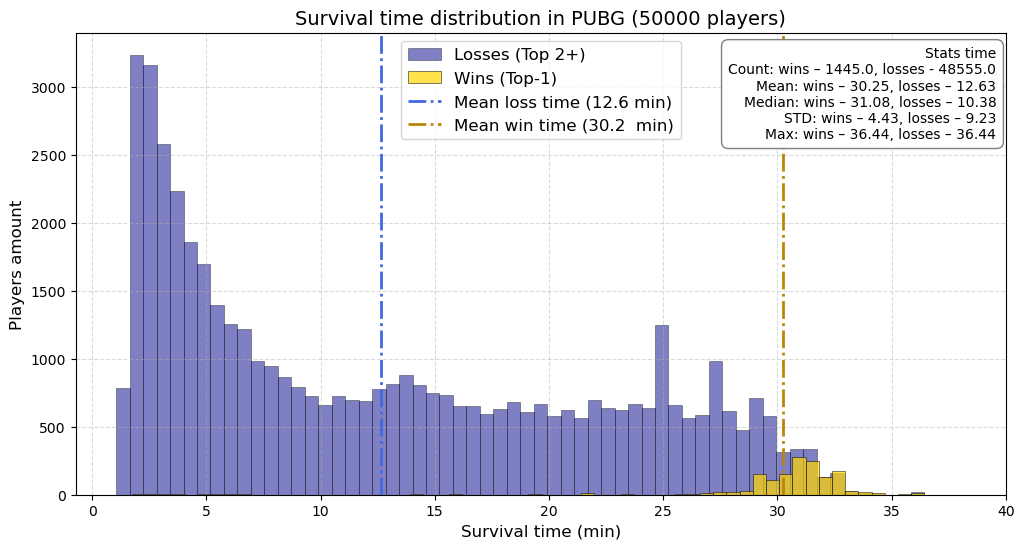

In [288]:
pubg_stat['survive_mins'] = pubg_stat['player_survive_time'] / 60 #Converts sirvive sec to min

plt.figure(figsize=(12, 6))

plt.hist(losses['survive_mins'], 
         bins=60,                   
         alpha=0.5,                 
         label='Losses (Top 2+)', 
         color='darkblue',          
         edgecolor='black',
         linewidth=0.5)

plt.hist(wins['survive_mins'], 
         bins=60, 
         alpha=0.7, 
         label='Wins (Top-1)', 
         color='gold',             
         edgecolor='black',
         linewidth=0.5)

plt.title(f"Survival time distribution in PUBG ({len(pubg_stat)} players)", fontsize=14)
plt.xlabel("Survival time (min)", fontsize=12)
plt.ylabel("Players amount", fontsize=12)

# wins['survive_mins'].describe()
# losses['survive_mins'].describe()
box_text = (
    f"Stats time\n"
    f"Count: wins – {wins['survive_mins'].describe()['count']}, losses - {round(losses['survive_mins'].describe()['count'], 2)}\n"
    f"Mean: wins – {round(wins['survive_mins'].describe()['mean'], 2)}, losses – {round(losses['survive_mins'].describe()['mean'], 2)}\n"
    f"Median: wins – {round(wins['survive_mins'].describe()['50%'], 2)}, losses – {round(losses['survive_mins'].describe()['50%'], 2)}\n"
    f"STD: wins – {round(wins['survive_mins'].describe()['std'], 2)}, losses – {round(losses['survive_mins'].describe()['std'], 2)}\n"
    f"Max: wins – {round(wins['survive_mins'].describe()['max'], 2)}, losses – {round(losses['survive_mins'].describe()['max'], 2)}"
)

plt.text(0.99, 0.97, box_text, transform=plt.gca().transAxes, 
         fontsize=10, verticalalignment='top', horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1, edgecolor='gray'))

plt.xticks(range(0, 45, 5)) #Range x line from 0 to 45 min with 5-min step

mean_loss_time = pubg_stat[pubg_stat['team_placement'] > 1]['survive_mins'].mean()

mean_win_time = pubg_stat[pubg_stat['team_placement'] == 1]['survive_mins'].mean()

plt.axvline(mean_loss_time, color='royalblue', linestyle='-.', linewidth=2, #line with mean spent time
            label=f'Mean loss time ({round(mean_loss_time, 1)} min)')

plt.axvline(mean_win_time, color='darkgoldenrod', linestyle='-.', linewidth=2, 
            label=f'Mean win time ({round(mean_win_time, 1)}  min)')

plt.grid(True, linestyle='--', alpha=0.45)
plt.legend(fontsize=12)                  

plt.show()
# wins['survive_mins'].describe()
# losses['survive_mins'].describe()

Survival time for losers has a sharp peak at 2-3 minutes, meaning many players are eliminated right after landing, followed by a long flat tail. The mean of 12.6 minutes is higher than the median of 10.4, which indicates right skew. Small peaks at 25 and 27 minutes are probably related to the zone-shrinking mechanic. Winners survive about 30-32 minutes with little spread (standard deviation 4.4), which is close to the natural match length. The maximum is the same for both groups (36.44 minutes), which is the length of the longest match.

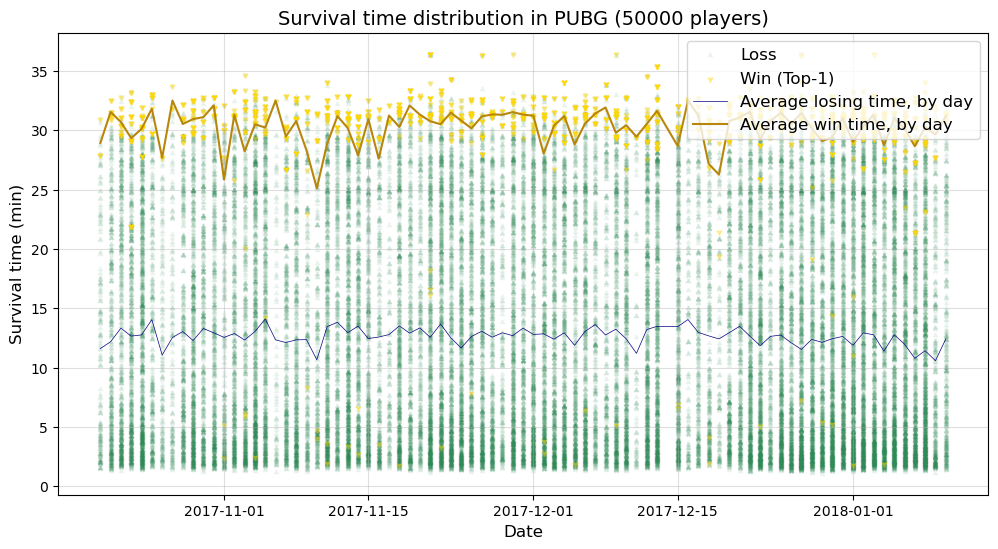

In [260]:
plt.figure(figsize=(12, 6))

plt.scatter(losses['only_date'],
            losses['survive_mins'], 
            color='seagreen',
            alpha=0.1, s=15,
            label='Loss', marker='2')

plt.scatter(wins['only_date'],
            wins['survive_mins'], 
            color='gold', alpha=0.5,
            s=20, label='Win (Top-1)',
           marker='1')

plt.title(f"Survival time distribution in PUBG ({len(pubg_stat)} players)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Survival time (min)", fontsize=12)

daily_loss_mean = losses.groupby('only_date')['survive_mins'].mean()
daily_win_mean = wins.groupby('only_date')['survive_mins'].mean()

plt.plot(daily_loss_mean.index, daily_loss_mean.values, 
         color='navy', 
         linestyle='-', 
         linewidth=.5, 
         label='Average losing time, by day')

plt.plot(daily_win_mean.index, daily_win_mean.values, 
         color='darkgoldenrod', 
         linestyle='-', 
         linewidth=1.5, 
         label='Average win time, by day')

plt.legend(fontsize=12, loc='upper right')
plt.grid(True, linestyle='-', alpha=0.4)

plt.show()

The daily average survival time is stable: about 30-32 minutes for winners and 12-13 minutes for losers, with no trend. The winners’ line fluctuates more because of the small sample. The chart itself is hard to read: points overlap and the legend covers part of the data. It would help to reduce point opacity, move the legend outside the plot, or use a boxplot or violin plot by week.

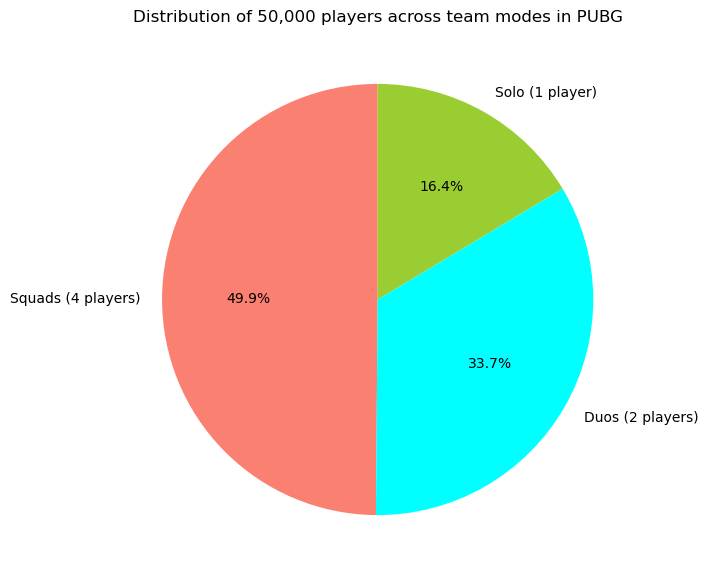

In [291]:
mode_counts = pubg_stat['party_size'].value_counts()
labels = mode_counts.index.map({1: 'Solo (1 player)', 2: 'Duos (2 players)', 4: 'Squads (4 players)'})

plt.figure(figsize=(7, 7))
plt.pie(mode_counts, labels=labels, autopct='%1.1f%%', colors=['salmon','aqua','yellowgreen'], startangle=90)
plt.title('Distribution of 50,000 players across team modes in PUBG')
plt.show()


By game mode, players are distributed as follows: Squads 49.9%, Duos 33.7%, Solo 16.4%. These are shares of players, not matches, so the actual share of Solo matches is higher.